# 🗄️ Forecasting Weekly Product Demand — Part 6: SQL Analysis

**Goal of this notebook:** put the cleaned data into a **SQL database** and answer business questions with SQL: which products and customers matter most, how sales move through the year, and whether the weekly demand table from Part 2 can be rebuilt exactly with SQL alone.

**Database:** SQLite. It is built into Python, so there is no database server to install or run: the whole database is one file.

**Input:** `data/retail.db`, built from the Part 1 and Part 2 outputs by:
```
python scripts/build_db.py
```
**Queries:** every query lives in its own file in `sql/queries/`, so it can be read and reused outside this notebook. The table definitions are in `sql/schema.sql`.

## 1. Connect to the Database

`src/db.py` has small helpers:
- `connect()` opens the database **read-only**, so no query here can change the data by mistake.
- `read_query(name)` returns the text of `sql/queries/<name>.sql`.
- `run_query(conn, name, **params)` runs it and returns a pandas DataFrame. Values such as "top 10" are passed as **named parameters** (`:top_n`), not pasted into the SQL text.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from src.db import RETAIL_DB, connect, read_query, run_query

pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"

conn = connect(RETAIL_DB)
print(f"Connected to {RETAIL_DB.name}")

Connected to retail.db


In [2]:
# every table in the database and its number of rows
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn)
tables["rows"] = [conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables["name"]]
tables

,name,rows
0,cleaning_log,8
1,products,4700
2,sales,997033
3,selected_products,100
4,weekly_demand,10400


📌 **Reading this:** The database has five tables:
- `sales`: the **997,033** clean invoice lines from Part 1 (one row per product on an invoice).
- `products`: one name for each of the **4,700** products.
- `selected_products`: the **100** products chosen for forecasting in Part 2, with their sales rank and demand pattern.
- `weekly_demand`: units per product per week for those 100 products (**100 × 104 = 10,400** rows).
- `cleaning_log`: how many rows each cleaning rule removed.

`sales.stock_code` is a **foreign key** to `products`, and `CHECK` rules in the schema refuse a quantity or price ≤ 0, so the cleaning rules from Part 1 are also enforced by the database itself.

## 2. Check the Database Against the Clean Data

Before using the database, we confirm it holds exactly the same data as `clean_sales.parquet`: same number of lines, units, revenue and invoices.

In [3]:
db = pd.read_sql("""
    SELECT COUNT(*)                AS lines,
           SUM(quantity)           AS units,
           ROUND(SUM(revenue), 2)  AS revenue,
           COUNT(DISTINCT invoice) AS invoices
    FROM sales
""", conn).iloc[0]

clean = pd.read_parquet(PROCESSED_DIR / "clean_sales.parquet")
checks = {
    "same number of lines": db["lines"] == len(clean),
    "same total units": db["units"] == clean["Quantity"].sum(),
    "same total revenue": db["revenue"] == round(clean["Revenue"].sum(), 2),
    "same number of invoices": db["invoices"] == clean["Invoice"].nunique(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} - {name}")

PASS - same number of lines
PASS - same total units
PASS - same total revenue
PASS - same number of invoices


📌 **Reading this:** All four checks pass, so nothing was lost or changed when the clean data was loaded into SQL. Every answer below is based on the same data as Parts 1–5.

## 3. Best-Selling Products

Which products sell the most units, and are they also the ones that bring in the most money? The query first adds up each product in a **CTE** (`WITH ...`), then ranks all products twice with the **window function** `RANK() OVER (...)`.

In [4]:
print(read_query("top_products"))

-- Best-selling products: rank by units sold and by revenue.
-- Parameter :top_n = how many products to return.

WITH product_totals AS (
    SELECT s.stock_code,
           p.name,
           SUM(s.quantity)           AS units,
           ROUND(SUM(s.revenue), 2)  AS revenue,
           COUNT(DISTINCT s.invoice) AS invoices
    FROM sales AS s
    JOIN products AS p ON p.stock_code = s.stock_code
    GROUP BY s.stock_code, p.name
)
SELECT RANK() OVER (ORDER BY units DESC)   AS units_rank,
       RANK() OVER (ORDER BY revenue DESC) AS revenue_rank,
       stock_code,
       name,
       units,
       revenue,
       invoices
FROM product_totals
ORDER BY units_rank
LIMIT :top_n;



In [5]:
top_products = run_query(conn, "top_products", top_n=10)
top_products

,units_rank,revenue_rank,stock_code,name,units,revenue,invoices
0,1,152,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,105659,24329.45,1013
1,2,3,85099B,JUMBO BAG RED RETROSPOT,96269,181143.30,3997
2,3,31,21212,PACK OF 72 RETROSPOT CAKE CASES,94108,51413.95,3106
3,4,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91355,252524.13,5432
4,5,8,22197,SMALL POPCORN HOLDER,88265,79347.30,2318
5,6,5,84879,ASSORTED COLOUR BIRD ORNAMENT,79632,128653.51,2800
6,7,299,17003,BROCADE RING PURSE,69633,14611.86,454
7,8,119,21977,PACK OF 60 PINK PAISLEY CAKE CASES,55889,27987.13,1985
8,9,128,84991,60 TEATIME FAIRY CAKE CASES,53812,26922.41,2120
9,10,94,15036,ASSORTED COLOURS SILK FAN,43432,32479.11,981


📌 **Reading this:** The top products by **units** are not the same as the top products by **revenue**:
- The #1 product by units, *World War 2 Gliders* (105,659 units), is only **#152 by revenue**, because it is very cheap (about £0.23 a unit).
- *White Hanging Heart T-Light Holder* is #4 by units but **#2 by revenue**, and it appears on the most invoices (5,432).
- Cake cases and small cheap items sell in bulk to wholesale customers.

For stock planning, **units** is the right measure (it is what takes shelf space and what we forecast). For deciding which forecast errors cost the most money, revenue matters too.

## 4. Sales by Month

Units, revenue, orders and customers for every month. `LAG(revenue, 12)` is a window function that looks **12 rows back**, so each month is compared with the same month one year earlier.

In [6]:
print(read_query("monthly_sales"))

-- Units, revenue, orders and customers per month,
-- plus revenue change against the same month one year earlier.

WITH monthly AS (
    SELECT strftime('%Y-%m', invoice_date) AS month,
           SUM(quantity)                   AS units,
           ROUND(SUM(revenue), 2)          AS revenue,
           COUNT(DISTINCT invoice)         AS invoices,
           COUNT(DISTINCT customer_id)     AS customers
    FROM sales
    GROUP BY month
)
SELECT month,
       units,
       revenue,
       invoices,
       customers,
       ROUND(revenue / invoices, 2) AS avg_invoice_value,
       ROUND(100.0 * (revenue - LAG(revenue, 12) OVER (ORDER BY month))
                   / LAG(revenue, 12) OVER (ORDER BY month), 1) AS revenue_yoy_pct
FROM monthly
ORDER BY month;



In [7]:
monthly = run_query(conn, "monthly_sales")
monthly

,month,units,revenue,invoices,customers,avg_invoice_value,revenue_yoy_pct
0,2009-12,420092,787091.13,1660,951,474.15,NaN
1,2010-01,386553,604989.13,1041,697,581.16,NaN
2,2010-02,374970,527479.74,1179,768,447.40,NaN
3,2010-03,520357,752881.54,1639,1048,459.35,NaN
4,2010-04,354419,627732.17,1429,937,439.28,NaN
5,2010-05,381866,623416.55,1477,962,422.08,NaN
6,2010-06,399866,685261.67,1607,1034,426.42,NaN
7,2010-07,331511,618098.61,1493,922,414.00,NaN
8,2010-08,382165,654804.61,1395,909,469.39,NaN
9,2010-09,573789,853381.80,1775,1131,480.78,NaN


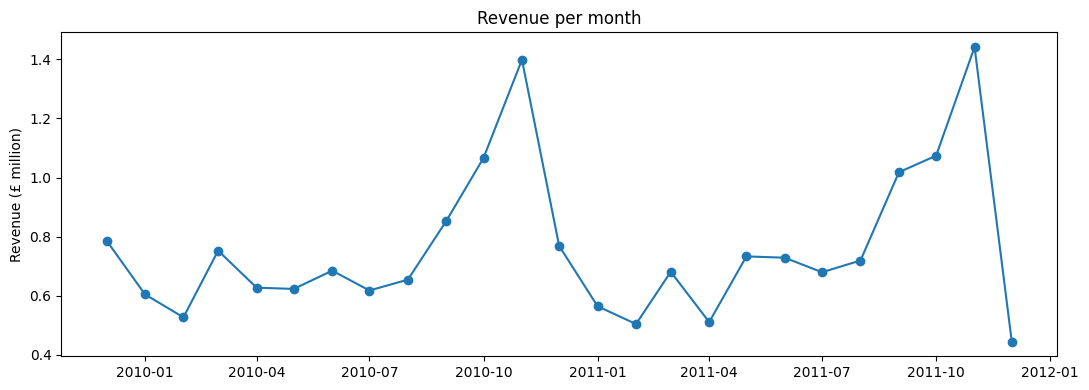

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pd.to_datetime(monthly["month"]), monthly["revenue"] / 1e6, marker="o", color="tab:blue")
ax.set_ylabel("Revenue (£ million)")
ax.set_title("Revenue per month")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- Both years have the same shape: flat from January to August, then a strong rise **from September to November**, the gift season. November is the best month in both years (£1.40M in 2010, **£1.44M** in 2011).
- Early 2011 was weaker than early 2010 (January–April down 4–19%), but from **May 2011 revenue was above the year before** (up to +19% in September).
- December 2011 shows −42% only because the data **stops on 9 December 2011**. It is a partial month, not a real drop.
- The average order is worth about **£410–£580**, which fits a shop where many customers are wholesalers.

## 5. Where the Revenue Comes From

Revenue by country, and each country's share of the total. `SUM(SUM(revenue)) OVER ()` is a window over **all** countries, so each row can be divided by the grand total in the same query.

In [9]:
print(read_query("country_share"))

-- Revenue by country and each country's share of total revenue.
-- Parameter :top_n = how many countries to return.

SELECT country,
       COUNT(DISTINCT customer_id) AS customers,
       COUNT(DISTINCT invoice)     AS invoices,
       ROUND(SUM(revenue), 2)      AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS revenue_share_pct
FROM sales
GROUP BY country
ORDER BY revenue DESC
LIMIT :top_n;



In [10]:
countries = run_query(conn, "country_share", top_n=10)
countries

,country,customers,invoices,revenue,revenue_share_pct
0,United Kingdom,5326,36034,16296526.03,85.4
1,EIRE,3,579,606229.73,3.2
2,Netherlands,22,214,546276.93,2.9
3,Germany,107,753,379981.15,2.0
4,France,93,598,296063.93,1.6
5,Australia,15,86,166769.80,0.9
6,Switzerland,22,84,93328.56,0.5
7,Spain,38,141,85092.83,0.4
8,Sweden,19,99,84523.74,0.4
9,Denmark,12,42,63478.19,0.3


📌 **Reading this:** The **United Kingdom brings 85.4%** of revenue. The next country, EIRE (Ireland), brings 3.2% from only **3 customers**, so these are large wholesale buyers. For forecasting, this means demand is mostly UK demand, which is why UK bank holidays are used as features in Part 4.

## 6. Biggest Customers

Customers with at least 50 orders, sorted by revenue. `HAVING` filters **after** grouping (on the number of orders per customer), while `WHERE` filters single sales lines before grouping (here: guest checkouts without a customer ID are left out).

In [11]:
print(read_query("top_customers"))

-- Customers with many orders, and how much of total revenue they bring.
-- Guest checkouts (no customer_id) are left out.
-- Parameters: :min_invoices = minimum number of orders, :top_n = rows to return.

WITH customer_totals AS (
    SELECT customer_id,
           country,
           COUNT(DISTINCT invoice)                 AS invoices,
           SUM(quantity)                           AS units,
           ROUND(SUM(revenue), 2)                  AS revenue,
           SUM(is_large_line)                      AS large_lines,
           MIN(date(invoice_date))                 AS first_order,
           MAX(date(invoice_date))                 AS last_order
    FROM sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id, country
    HAVING COUNT(DISTINCT invoice) >= :min_invoices
)
SELECT customer_id,
       country,
       invoices,
       units,
       revenue,
       ROUND(100.0 * revenue / (SELECT SUM(revenue) FROM sales), 2) AS revenue_share_pct,
       large_lines,
       

In [12]:
customers = run_query(conn, "top_customers", min_invoices=50, top_n=10)
customers

,customer_id,country,invoices,units,revenue,revenue_share_pct,large_lines,first_order,last_order
0,18102,United Kingdom,145,181173,579128.64,3.04,2,2009-12-01,2011-12-09
1,14646,Netherlands,143,365112,523375.74,2.74,5,2009-12-02,2011-12-08
2,14156,EIRE,144,162490,298283.75,1.56,2,2009-12-01,2011-11-30
3,14911,EIRE,371,141714,259854.49,1.36,0,2009-12-01,2011-12-08
4,13694,United Kingdom,142,185419,191279.15,1.00,6,2009-12-04,2011-12-06
5,17511,United Kingdom,60,115774,169710.87,0.89,0,2009-12-02,2011-12-07
6,16684,United Kingdom,53,101192,141955.55,0.74,1,2009-12-07,2011-12-05
7,15061,United Kingdom,126,73805,125720.73,0.66,0,2009-12-01,2011-12-06
8,15311,United Kingdom,207,69236,113081.72,0.59,1,2009-12-01,2011-12-09
9,13089,United Kingdom,200,58266,111120.29,0.58,0,2009-12-02,2011-12-07


📌 **Reading this:**
- The largest customer brings **3.0%** of all revenue on their own, and the top two together bring almost **6%**.
- Customer 14646 (Netherlands) bought **365,112 units** in 143 orders, about 2,500 units per order, which is clearly a wholesaler.
- All ten top customers ordered across the **whole two years** (first order in December 2009, last in late 2011), so they are regular buyers, not one-off bulk orders.

This explains part of the noise in weekly demand: one regular wholesaler placing or skipping an order can move a product's weekly units a lot. It is also why bulk-order weeks are capped before modelling.

## 7. Seasonal Profile of the 100 Forecast Products

Units sold by the 100 selected products in each calendar month, one column per year. The `CASE WHEN` inside `SUM(...)` puts each year into its own column (a **pivot** done in SQL).

In [13]:
print(read_query("seasonal_profile"))

-- Units sold by the 100 selected products in each calendar month,
-- with one column per year so the two gift seasons can be compared side by side.

SELECT CAST(strftime('%m', s.invoice_date) AS INTEGER) AS month_no,
       SUM(CASE WHEN strftime('%Y', s.invoice_date) = '2010' THEN s.quantity ELSE 0 END) AS units_2010,
       SUM(CASE WHEN strftime('%Y', s.invoice_date) = '2011' THEN s.quantity ELSE 0 END) AS units_2011
FROM sales AS s
JOIN selected_products AS sp ON sp.stock_code = s.stock_code
GROUP BY month_no
ORDER BY month_no;



In [14]:
season = run_query(conn, "seasonal_profile")
season

,month_no,units_2010,units_2011
0,1,86108,77031
1,2,91228,76492
2,3,142998,116752
3,4,114119,89702
4,5,122974,118795
5,6,138158,96678
6,7,109554,97496
7,8,121247,110820
8,9,154697,119955
9,10,163464,115798


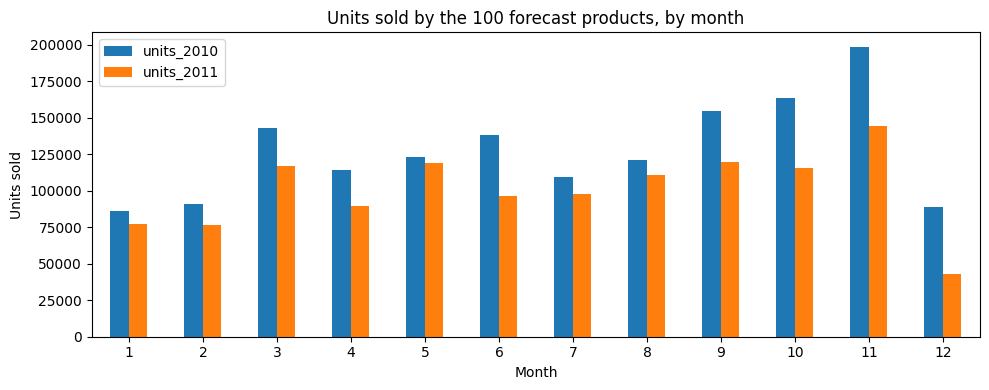

In [15]:
ax = season.set_index("month_no")[["units_2010", "units_2011"]].plot(
    kind="bar", figsize=(10, 4), color=["tab:blue", "tab:orange"], rot=0)
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")
ax.set_title("Units sold by the 100 forecast products, by month")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The **gift-season peak** is clear in both years: units rise from September and peak in **November**. December is low because the shop closes over Christmas, and December 2011 is also a partial month.
- These 100 products sold **less in 2011 than in 2010 in every month**, even though the shop's total revenue grew from May 2011 (Section 4). New products took a bigger share of sales in 2011.

This matters for the model: "the same week last year" overstates 2011 demand for many of these products, which is why Part 4 also uses a **year-over-year level ratio** (`yoy_ratio`) instead of copying last year's numbers.

## 8. Weekly Demand Rebuilt in SQL

In Part 2, the weekly demand table was built with pandas. Here we build it again with **one SQL query**, using the same rules:
- A week starts on **Monday**: `date(invoice_date, 'weekday 0', '-6 days')` moves each date to the next Sunday, then 6 days back.
- The first and last weeks of the data are **partial**, so they are dropped.
- A **recursive CTE** lists every Monday in the range, and a `CROSS JOIN` with the 100 products makes the full product × week grid.
- A `LEFT JOIN` adds the units sold, and `COALESCE(..., 0)` fills weeks with no sales with **0**.

If the SQL result matches `weekly_demand.parquet` exactly, the pandas pipeline is confirmed by a second, independent method.

In [16]:
print(read_query("weekly_demand"))

-- Weekly demand for the 100 selected products, built from the clean sales lines.
-- Same rules as notebook 02:
--   * a week starts on Monday
--   * the first and last weeks of the data are partial, so they are dropped
--   * a week with no sales gets 0 units
-- Result: one row per product per week.

WITH sale_weeks AS (
    SELECT stock_code,
           date(invoice_date, 'weekday 0', '-6 days') AS week,   -- Monday of the sale's week
           quantity
    FROM sales
),
week_range AS (
    SELECT date(MIN(week), '+7 days') AS first_week,              -- skip the partial first week
           date(MAX(week), '-7 days') AS last_week                -- skip the partial last week
    FROM sale_weeks
),
weeks (week) AS (                                                 -- every Monday in the range
    SELECT first_week FROM week_range
    UNION ALL
    SELECT date(week, '+7 days')
    FROM weeks
    WHERE week < (SELECT last_week FROM week_range)
),
product_weeks AS (
    SELECT stock_cod

In [17]:
weekly_sql = run_query(conn, "weekly_demand")

weekly_pandas = pd.read_parquet(PROCESSED_DIR / "weekly_demand.parquet")
weekly_pandas = pd.DataFrame({
    "stock_code": weekly_pandas["StockCode"].astype(str),
    "week": weekly_pandas["week"].dt.strftime("%Y-%m-%d"),
    "units": weekly_pandas["units"],
}).sort_values(["stock_code", "week"]).reset_index(drop=True)

checks = {
    "same number of rows": len(weekly_sql) == len(weekly_pandas),
    "same products": set(weekly_sql["stock_code"]) == set(weekly_pandas["stock_code"]),
    "same weeks": weekly_sql["week"].unique().tolist() == weekly_pandas["week"].unique().tolist(),
    "same units in every product-week": (weekly_sql["units"].to_numpy() == weekly_pandas["units"].to_numpy()).all(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} - {name}")

print(f"\nRows: {len(weekly_sql):,}  |  weeks: {weekly_sql['week'].min()} to {weekly_sql['week'].max()}")

PASS - same number of rows
PASS - same products
PASS - same weeks
PASS - same units in every product-week

Rows: 10,400  |  weeks: 2009-12-07 to 2011-11-28


📌 **Reading this:** All four checks pass. The SQL query gives **exactly the same 10,400 product-week values** as the pandas code in Part 2: the same 104 weeks (7 Dec 2009 to 28 Nov 2011), the same partial weeks dropped and the same zero-filled weeks. The training data for the model can be produced either way.

## 9. Demand Patterns of the Forecast Products

How the 100 products split across the demand patterns from Part 2, and how often each group has a week with **no sales**. This query joins two tables: `selected_products` (pattern, ADI, CV²) and a summary of `weekly_demand`.

In [18]:
print(read_query("demand_patterns"))

-- How the 100 selected products split across demand patterns (smooth, erratic,
-- intermittent, lumpy), and how often each group has a week with no sales.

WITH product_weeks AS (
    SELECT stock_code,
           SUM(units)      AS units,
           SUM(units = 0)  AS zero_weeks,
           COUNT(*)        AS weeks
    FROM weekly_demand
    GROUP BY stock_code
)
SELECT sp.pattern,
       COUNT(*)                                          AS products,
       ROUND(AVG(sp.adi), 2)                             AS avg_adi,
       ROUND(AVG(sp.cv2), 2)                             AS avg_cv2,
       SUM(pw.units)                                     AS units,
       ROUND(100.0 * SUM(pw.zero_weeks) / SUM(pw.weeks), 1) AS pct_zero_weeks
FROM selected_products AS sp
JOIN product_weeks AS pw ON pw.stock_code = sp.stock_code
GROUP BY sp.pattern
ORDER BY products DESC;



In [19]:
patterns = run_query(conn, "demand_patterns")
patterns

,pattern,products,avg_adi,avg_cv2,units,pct_zero_weeks
0,erratic,66,1.06,1.42,1719007,5.7
1,smooth,31,1.05,0.34,990960,4.3
2,lumpy,3,1.40,2.14,62754,28.5


📌 **Reading this:** **66 products are erratic** (they sell almost every week, but the amount jumps a lot), **31 are smooth** and only **3 are lumpy**. The lumpy products have no sales in **28.5%** of weeks, against about 5% for the others. These groups match the error analysis in Part 5: smooth products are forecast well, erratic and lumpy ones are much harder.

In [20]:
conn.close()

## 10. Summary

**What was built**
- A SQLite database (`data/retail.db`) with 5 tables, primary keys, foreign keys, `CHECK` rules and indexes (`sql/schema.sql`), loaded by `scripts/build_db.py`.
- 7 reusable queries in `sql/queries/` (Part 7 later adds an eighth, `weekly_orders.sql`), using joins, `GROUP BY` / `HAVING`, CTEs, a recursive CTE, window functions (`RANK`, `LAG`, `SUM OVER`), `CASE WHEN` pivots and date functions.
- A small second database (`data/app.db`) that the FastAPI app reads with SQL at startup.

**What the data says**
- Best sellers by units are not the best by revenue: the #1 product by units is only #152 by revenue.
- The UK brings 85% of revenue, and a few regular wholesale customers bring a large share on their own.
- Sales peak from September to November in both years; the 100 forecast products sold less in 2011 than in 2010, so last year's numbers must be adjusted, not copied.

**Checks**
- The database matches the clean data exactly (lines, units, revenue, invoices).
- Weekly demand rebuilt in SQL matches the pandas result from Part 2 for all 10,400 product-weeks.